In [16]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
car=pd.read_csv('/content/car_age_price.csv')
car.head()

,Year,Price
0,2018,465000
1,2019,755000
2,2019,700000
3,2018,465000
4,2018,465000


In [4]:
car.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112 entries, 0 to 111
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Year    112 non-null    int64
 1   Price   112 non-null    int64
dtypes: int64(2)
memory usage: 1.9 KB


In [5]:
car.isna().sum()

,0
Year,0
Price,0


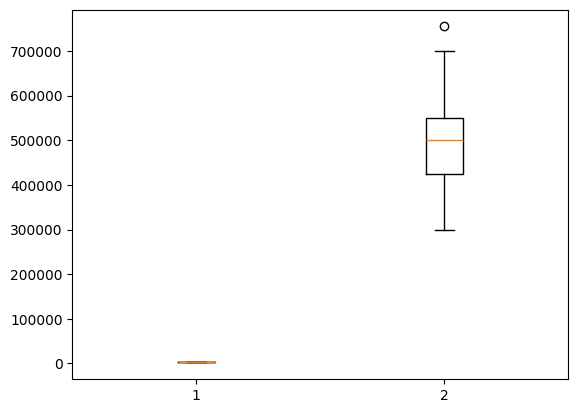

In [6]:
plt.boxplot(car)
plt.show()

Using linear regression

In [8]:
x=car.drop('Price',axis=1)
y=car['Price']

In [9]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [10]:
from sklearn .linear_model import LinearRegression
lr=LinearRegression()

In [12]:
model=lr.fit(x_train,y_train)
y_pred= model.predict(x_test)
from sklearn.metrics import mean_squared_error,r2_score
print(mean_squared_error(y_test,y_pred))
print(r2_score(y_test,y_pred))

4326906256.829671
0.36759313425902185


In [13]:
y_test

,Price
40,525000
65,495000
4,465000
47,450000
42,550000
69,300000
26,550000
11,500000
10,500000
44,550000


In [14]:
y_pred

array([600775.91252081, 505558.77690466, 553167.34471273, 553167.34471273,
       553167.34471273, 410341.6412885 , 505558.77690466, 553167.34471273,
       600775.91252081, 600775.91252081, 315124.50567235, 505558.77690466,
       410341.6412885 , 648384.48032889, 553167.34471273, 600775.91252081,
       315124.50567235, 410341.6412885 , 505558.77690466, 505558.77690466,
       505558.77690466, 505558.77690466, 505558.77690466])

In [15]:
x_test

,Year
40,2019
65,2017
4,2018
47,2018
42,2018
69,2015
26,2017
11,2018
10,2019
44,2019


In [17]:
price_predict = model.predict(pd.DataFrame([[2014]], columns=['Year']))
price_predict

array([362733.07348043])

#Using lasso regression

In [19]:
x1 = car.drop(['Price'], axis = 1)
y1 = car['Price']

In [20]:
from sklearn.model_selection import train_test_split
x_train1,x_test1,y_train1,y_test1 = train_test_split(x1,y1,test_size= 0.2, random_state=42)

In [21]:
from sklearn.linear_model import LassoCV

In [22]:
lasso = LassoCV(cv=5, random_state=42)
lasso.fit(x_train1, y_train1)

LassoCV(cv=5, random_state=42)

In [23]:
y_pred1 = lasso.predict(x_test1)

In [24]:
y_pred1

array([600659.83320381, 505537.91472328, 553098.87396353, 553098.87396353,
       553098.87396353, 410415.99624273, 505537.91472328, 553098.87396353,
       600659.83320381, 600659.83320381, 315294.0777622 , 505537.91472328,
       410415.99624273, 648220.79244408, 553098.87396353, 600659.83320381,
       315294.0777622 , 410415.99624273, 505537.91472328, 505537.91472328,
       505537.91472328, 505537.91472328, 505537.91472328])

In [25]:
from sklearn.metrics import mean_squared_error,r2_score
print(mean_squared_error(y_test1,y_pred1))
print(r2_score(y_test1,y_pred1))

4321545148.999522
0.3683766967395845


In [26]:
price_predict_1 = lasso.predict(pd.DataFrame([[2014]], columns=['Year']))
price_predict_1

array([362855.03700246])